# Brain Tumor MRI Dataset Leakage Audit

Checking internal train/test leakage and cross-dataset overlap across 7 public brain tumor datasets, then a patient-level vs naive-split experiment on Figshare.

In [1]:
!pip install imagehash scikit-image opencv-python -q

## 1. Build manifest

In [2]:
import os, csv, hashlib
from PIL import Image
import imagehash

ROOT = "/kaggle/input/datasets/nasiruddin66/brain-tumor-datasets/Brain Tumor Datasets"
OUTPUT_CSV = "/kaggle/working/manifest.csv"

DATASET_FOLDERS = [
    "BDNeuro-HIra", "BRISC", "Br35H", "Brain_Cancer_Mizanur",
    "Masoud Nickparvar", "Shartaj", "figshare"
]
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def guess_split(parts):
    for p in parts:
        low = p.lower()
        if low in ('train','training'): return 'train'
        if low in ('test','testing'): return 'test'
        if low in ('val','validation'): return 'val'
    return 'none'

def guess_label(parts):
    for p in reversed(parts):
        if p.lower() not in ('train','training','test','testing','val','validation'):
            return p
    return 'unknown'

rows = []
for dataset_name in DATASET_FOLDERS:
    dataset_root = os.path.join(ROOT, dataset_name)
    if not os.path.isdir(dataset_root):
        print(f"missing: {dataset_root}")
        continue
    count_before = len(rows)
    for dirpath, _, files in os.walk(dataset_root):
        for fname in files:
            if not fname.lower().endswith(IMG_EXTS):
                continue
            fpath = os.path.join(dirpath, fname)
            rel = os.path.relpath(fpath, dataset_root)
            parts = rel.split(os.sep)[:-1]
            try:
                img = Image.open(fpath).convert('L')
                rows.append({
                    'dataset': dataset_name, 'filename': fname, 'filepath': fpath,
                    'split': guess_split(parts), 'label': guess_label(parts),
                    'sha256': sha256_of(fpath),
                    'phash': str(imagehash.phash(img)),
                    'dhash': str(imagehash.dhash(img)),
                })
            except Exception as e:
                print(f"skip {fpath}: {e}")
    print(f"{dataset_name}: {len(rows)-count_before} images")

with open(OUTPUT_CSV, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys())
    w.writeheader()
    w.writerows(rows)
print(f"\nmanifest saved, {len(rows)} images total")

BDNeuro-HIra: 5941 images
BRISC: 6000 images
Br35H: 3000 images
Brain_Cancer_Mizanur: 6056 images
Masoud Nickparvar: 7200 images
Shartaj: 3264 images
figshare: 3064 images

manifest saved, 34525 images total


In [3]:
import pandas as pd
df = pd.read_csv("/kaggle/working/manifest.csv")
print(df.shape)
print(df.groupby(['dataset','split']).size())

(34525, 8)
dataset               split
BDNeuro-HIra          test      889
                      train    4160
                      val       892
BRISC                 test     1000
                      train    5000
Br35H                 none     3000
Brain_Cancer_Mizanur  none     6056
Masoud Nickparvar     test     1600
                      train    5600
Shartaj               test      394
                      train    2870
figshare              none     3064
dtype: int64


## 2. Internal leakage (train vs test/val, same dataset)

pHash + dHash agreement, Hamming distance <= 8. Preprocessing is consistent within one dataset so this is reliable here (unlike across datasets, see section 3).

In [4]:
import numpy as np
from scipy.spatial.distance import cdist
import cv2
from skimage.metrics import structural_similarity as ssim

df['phash_bits'] = df['phash'].apply(lambda x: [(int(x,16)>>i)&1 for i in range(64)])
df['dhash_bits'] = df['dhash'].apply(lambda x: [(int(x,16)>>i)&1 for i in range(64)])

def rotation_aware_ssim(path1, path2, size=(256,256)):
    img1 = cv2.imread(path1, cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(path2, cv2.IMREAD_GRAYSCALE)
    if img1 is None or img2 is None:
        return None, None
    img1 = cv2.resize(img1, size)
    img2 = cv2.resize(img2, size)
    best, best_o = -1, None
    for angle in [0,90,180,270]:
        if angle == 0: r = img2
        elif angle == 90: r = cv2.rotate(img2, cv2.ROTATE_90_CLOCKWISE)
        elif angle == 180: r = cv2.rotate(img2, cv2.ROTATE_180)
        else: r = cv2.rotate(img2, cv2.ROTATE_90_COUNTERCLOCKWISE)
        flip = cv2.flip(r, 1)
        for variant, label in [(r, f'rot{angle}'), (flip, f'rot{angle}_flip')]:
            s, _ = ssim(img1, variant, full=True)
            if s > best:
                best, best_o = s, label
    return best, best_o

def categorize(s):
    if s is None: return 'unreadable'
    if s >= 0.95: return 'A_true_duplicate'
    if s >= 0.70: return 'B_adjacent_slice'
    return 'C_false_alarm'

def internal_leakage(dataset_name, threshold=8):
    sub = df[df['dataset'] == dataset_name]
    if 'train' not in sub['split'].unique():
        return None
    train = sub[sub['split']=='train'].reset_index(drop=True)
    eval_splits = [s for s in ['test','val'] if s in sub['split'].unique()]

    train_p = np.array(train['phash_bits'].tolist())
    train_d = np.array(train['dhash_bits'].tolist())

    pairs = []
    for split in eval_splits:
        ev = sub[sub['split']==split].reset_index(drop=True)
        ev_p = np.array(ev['phash_bits'].tolist())
        ev_d = np.array(ev['dhash_bits'].tolist())
        pdist = cdist(ev_p, train_p, metric='hamming')*64
        ddist = cdist(ev_d, train_d, metric='hamming')*64
        both = (pdist<=threshold)&(ddist<=threshold)
        for i in range(len(ev)):
            m = np.where(both[i])[0]
            if len(m):
                j = m[0]
                s, o = rotation_aware_ssim(ev.loc[i,'filepath'], train.loc[j,'filepath'])
                pairs.append({'dataset':dataset_name,'eval_split':split,
                              'eval_file':ev.loc[i,'filename'],'eval_path':ev.loc[i,'filepath'],
                              'train_file':train.loc[j,'filename'],'train_path':train.loc[j,'filepath'],
                              'ssim':s,'category':categorize(s)})
    return pd.DataFrame(pairs)

internal_results = []
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    r = internal_leakage(name)
    if r is not None and len(r):
        internal_results.append(r)
internal_df = pd.concat(internal_results, ignore_index=True)
internal_df.to_csv("/kaggle/working/internal_leakage_final.csv", index=False)

sizes = df[df['split'].isin(['test','val'])].groupby(['dataset','split']).size()
summary = internal_df.groupby(['dataset','eval_split','category']).size().unstack(fill_value=0)
print(sizes)
print()
print(summary)

dataset            split
BDNeuro-HIra       test      889
                   val       892
BRISC              test     1000
Masoud Nickparvar  test     1600
Shartaj            test      394
dtype: int64

category                      A_true_duplicate  B_adjacent_slice  \
dataset           eval_split                                       
BDNeuro-HIra      test                       0                73   
                  val                        1                82   
BRISC             test                      94               154   
Masoud Nickparvar test                     210               326   
Shartaj           test                     222                22   

category                      C_false_alarm  
dataset           eval_split                 
BDNeuro-HIra      test                  245  
                  val                   243  
BRISC             test                  337  
Masoud Nickparvar test                  495  
Shartaj           test                   31

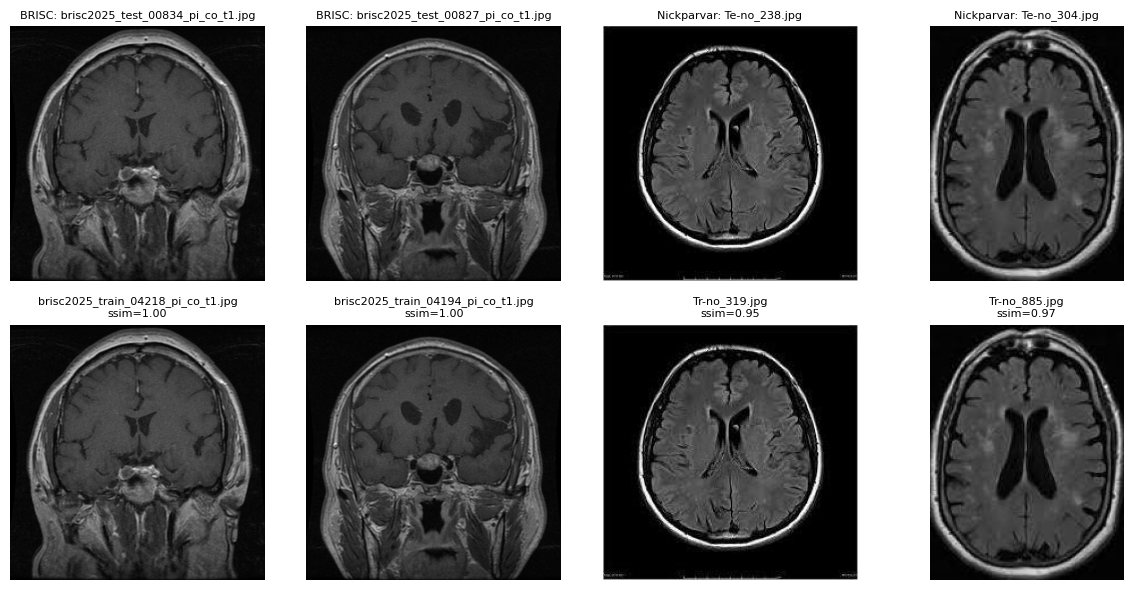

In [5]:
# Fig 1: example internal duplicate pairs (2 from BRISC, 2 from Nickparvar)
import matplotlib.pyplot as plt
from PIL import Image

def show_pairs(frames_with_labels, save_as=None):
    # frames_with_labels: list of (dataset_label, one-row-dataframe-slice)
    n = len(frames_with_labels)
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6))
    if n == 1: axes = axes.reshape(2,1)
    for col, (dname, r) in enumerate(frames_with_labels):
        axes[0,col].imshow(Image.open(r['eval_path']), cmap='gray'); axes[0,col].axis('off')
        axes[0,col].set_title(f"{dname}: {r['eval_file']}", fontsize=8)
        axes[1,col].imshow(Image.open(r['train_path']), cmap='gray'); axes[1,col].axis('off')
        axes[1,col].set_title(f"{r['train_file']}\nssim={r['ssim']:.2f}", fontsize=8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()

brisc_ex = internal_df[(internal_df['dataset']=='BRISC') & (internal_df['category']=='A_true_duplicate')].head(2)
nick_ex = internal_df[(internal_df['dataset']=='Masoud Nickparvar') & (internal_df['category']=='A_true_duplicate')].head(2)

pairs = [('BRISC', r) for _,r in brisc_ex.iterrows()] + [('Nickparvar', r) for _,r in nick_ex.iterrows()]
show_pairs(pairs, save_as='/kaggle/working/fig1_example_duplicates.png')

## 3. Cross-dataset overlap

pHash/dHash fail here (different crop/contrast/compression per dataset shifts the hash even for identical scans - confirmed this the hard way). Using CNN embedding cosine similarity instead, checked across 4 rotations x flip since some datasets disguise reused images this way.

In [6]:
import torch, torchvision.models as models, torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
resnet.fc = torch.nn.Identity()
resnet = resnet.to(device).eval()

transform = T.Compose([
    T.Resize((224,224)),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s] 


In [7]:
# cache 8-orientation embeddings per dataset, batched for speed
import os
CACHE_DIR = "/kaggle/working/embeddings_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
BATCH_SIZE = 64

def make_orientations(filepath):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None: return None
    out = []
    for angle in [0,90,180,270]:
        if angle==0: r = img
        elif angle==90: r = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
        elif angle==180: r = cv2.rotate(img, cv2.ROTATE_180)
        else: r = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
        flip = cv2.flip(r,1)
        out.append(Image.fromarray(r).convert('RGB'))
        out.append(Image.fromarray(flip).convert('RGB'))
    return out

def cache_embeddings(dataset_name):
    safe = dataset_name.replace(' ','_')
    emb_path = os.path.join(CACHE_DIR, f"{safe}_emb.npy")
    meta_path = os.path.join(CACHE_DIR, f"{safe}_meta.csv")
    if os.path.exists(emb_path):
        print(f"{dataset_name}: already cached")
        return
    sub = df[df['dataset']==dataset_name].reset_index(drop=True)
    n = len(sub)
    all_emb = np.zeros((n,8,2048), dtype=np.float32)
    for start in range(0, n, BATCH_SIZE):
        end = min(start+BATCH_SIZE, n)
        tensors, valid = [], []
        for i in range(start, end):
            variants = make_orientations(sub.loc[i,'filepath'])
            if variants is None:
                valid.append(False); continue
            valid.append(True)
            for v in variants: tensors.append(transform(v))
        if not tensors: continue
        batch = torch.stack(tensors).to(device)
        with torch.no_grad():
            out = resnet(batch).cpu().numpy()
        idx = 0
        for off, i in enumerate(range(start,end)):
            if valid[off]:
                all_emb[i] = out[idx:idx+8]; idx += 8
        if start % (BATCH_SIZE*10) == 0:
            print(f"  {dataset_name}: {end}/{n}")
    np.save(emb_path, all_emb)
    sub.to_csv(meta_path, index=False)
    print(f"{dataset_name}: cached {n}")

for name in ["BDNeuro-HIra","BRISC","Br35H","Brain_Cancer_Mizanur",
             "Masoud Nickparvar","Shartaj","figshare"]:
    cache_embeddings(name)

  BDNeuro-HIra: 64/5941
  BDNeuro-HIra: 704/5941
  BDNeuro-HIra: 1344/5941
  BDNeuro-HIra: 1984/5941
  BDNeuro-HIra: 2624/5941
  BDNeuro-HIra: 3264/5941
  BDNeuro-HIra: 3904/5941
  BDNeuro-HIra: 4544/5941
  BDNeuro-HIra: 5184/5941
  BDNeuro-HIra: 5824/5941
BDNeuro-HIra: cached 5941
  BRISC: 64/6000
  BRISC: 704/6000
  BRISC: 1344/6000
  BRISC: 1984/6000
  BRISC: 2624/6000
  BRISC: 3264/6000
  BRISC: 3904/6000
  BRISC: 4544/6000
  BRISC: 5184/6000
  BRISC: 5824/6000
BRISC: cached 6000
  Br35H: 64/3000
  Br35H: 704/3000
  Br35H: 1344/3000
  Br35H: 1984/3000
  Br35H: 2624/3000
Br35H: cached 3000
  Brain_Cancer_Mizanur: 64/6056
  Brain_Cancer_Mizanur: 704/6056
  Brain_Cancer_Mizanur: 1344/6056
  Brain_Cancer_Mizanur: 1984/6056
  Brain_Cancer_Mizanur: 2624/6056
  Brain_Cancer_Mizanur: 3264/6056
  Brain_Cancer_Mizanur: 3904/6056
  Brain_Cancer_Mizanur: 4544/6056
  Brain_Cancer_Mizanur: 5184/6056
  Brain_Cancer_Mizanur: 5824/6056
Brain_Cancer_Mizanur: cached 6056
  Masoud Nickparvar: 64/7200


In [8]:
# sanity check: random unrelated pairs should score much lower than real duplicates
from sklearn.metrics.pairwise import cosine_similarity
import random

def load_cached(dataset_name):
    safe = dataset_name.replace(' ','_')
    emb = np.load(os.path.join(CACHE_DIR, f"{safe}_emb.npy"))
    meta = pd.read_csv(os.path.join(CACHE_DIR, f"{safe}_meta.csv"))
    return emb, meta

def random_baseline(source_name, target_name, n=300):
    src_emb, src_meta = load_cached(source_name)
    tgt_emb, tgt_meta = load_cached(target_name)
    scores = []
    for _ in range(n):
        i = random.randrange(len(src_meta)); j = random.randrange(len(tgt_meta))
        scores.append(cosine_similarity(src_emb[i,0:1], tgt_emb[j,0:1])[0,0])
    return np.array(scores)

baseline = random_baseline("Brain_Cancer_Mizanur", "BRISC")
print(f"random pairs: mean={baseline.mean():.3f} median={np.median(baseline):.3f} "
      f"95th pct={np.percentile(baseline,95):.3f} max={baseline.max():.3f}")
print("real duplicates in this study consistently score 0.95+, so threshold 0.95 is safe")

random pairs: mean=0.604 median=0.613 95th pct=0.736 max=0.813
real duplicates in this study consistently score 0.95+, so threshold 0.95 is safe


In [9]:
COSINE_THRESHOLD = 0.95

def cross_dataset_match(source_name, target_name, thresh=COSINE_THRESHOLD):
    src_emb, src_meta = load_cached(source_name)
    tgt_emb, tgt_meta = load_cached(target_name)
    n_src, n_tgt = len(src_meta), len(tgt_meta)
    src_flat = src_emb.reshape(n_src*8, 2048)
    tgt_flat = tgt_emb.reshape(n_tgt*8, 2048)

    print(f"{source_name} ({n_src}) vs {target_name} ({n_tgt})")
    sim = cosine_similarity(src_flat, tgt_flat).reshape(n_src,8,n_tgt,8).max(axis=(1,3))
    best_idx = sim.argmax(axis=1)
    best_score = sim.max(axis=1)
    mask = best_score >= thresh

    rows = []
    for i in np.where(mask)[0]:
        j = best_idx[i]
        rows.append({'source_dataset':source_name,'target_dataset':target_name,
                      'source_file':src_meta.loc[i,'filename'],'source_path':src_meta.loc[i,'filepath'],
                      'target_file':tgt_meta.loc[j,'filename'],'target_path':tgt_meta.loc[j,'filepath'],
                      'cosine_sim':best_score[i]})
    out = pd.DataFrame(rows)
    print(f"  confirmed: {len(out)}/{n_src} ({100*len(out)/n_src:.2f}%)")
    return out

PAIRS = [
    ("Masoud Nickparvar","figshare"), ("BRISC","figshare"),
    ("Shartaj","figshare"), ("Br35H","figshare"),
    ("Br35H","Shartaj"), ("Br35H","Masoud Nickparvar"), ("Br35H","BDNeuro-HIra"),
    ("Brain_Cancer_Mizanur","figshare"), ("Brain_Cancer_Mizanur","Masoud Nickparvar"),
    ("Brain_Cancer_Mizanur","Shartaj"), ("Brain_Cancer_Mizanur","BRISC"), ("Brain_Cancer_Mizanur","Br35H"),
    ("BDNeuro-HIra","figshare"), ("BDNeuro-HIra","Masoud Nickparvar"),
    ("BDNeuro-HIra","Shartaj"), ("BDNeuro-HIra","BRISC"),
]

cross_results = {}
for src, tgt in PAIRS:
    key = f"{src}__vs__{tgt}"
    cross_results[key] = cross_dataset_match(src, tgt)
    cross_results[key].to_csv(f"/kaggle/working/cross_{key.replace(' ','_')}.csv", index=False)

Masoud Nickparvar (7200) vs figshare (3064)
  confirmed: 4940/7200 (68.61%)
BRISC (6000) vs figshare (3064)
  confirmed: 4527/6000 (75.45%)
Shartaj (3264) vs figshare (3064)
  confirmed: 2348/3264 (71.94%)
Br35H (3000) vs figshare (3064)
  confirmed: 2/3000 (0.07%)
Br35H (3000) vs Shartaj (3264)
  confirmed: 1117/3000 (37.23%)
Br35H (3000) vs Masoud Nickparvar (7200)
  confirmed: 1717/3000 (57.23%)
Br35H (3000) vs BDNeuro-HIra (5941)
  confirmed: 1568/3000 (52.27%)
Brain_Cancer_Mizanur (6056) vs figshare (3064)
  confirmed: 676/6056 (11.16%)
Brain_Cancer_Mizanur (6056) vs Masoud Nickparvar (7200)
  confirmed: 1830/6056 (30.22%)
Brain_Cancer_Mizanur (6056) vs Shartaj (3264)
  confirmed: 1171/6056 (19.34%)
Brain_Cancer_Mizanur (6056) vs BRISC (6000)
  confirmed: 1646/6056 (27.18%)
Brain_Cancer_Mizanur (6056) vs Br35H (3000)
  confirmed: 1/6056 (0.02%)
BDNeuro-HIra (5941) vs figshare (3064)
  confirmed: 3326/5941 (55.98%)
BDNeuro-HIra (5941) vs Masoud Nickparvar (7200)
  confirmed: 4250/5

## 4. Summary tables

In [10]:
cross_summary = []
for key, r in cross_results.items():
    src, tgt = key.split("__vs__")
    n_src = len(df[df['dataset']==src])
    cross_summary.append({'source':src,'target':tgt,'source_size':n_src,
                           'confirmed_matches':len(r),
                           'pct':round(100*len(r)/n_src,2)})
cross_summary_df = pd.DataFrame(cross_summary).sort_values('pct', ascending=False)
cross_summary_df.to_csv("/kaggle/working/SUMMARY_cross_dataset.csv", index=False)
cross_summary_df

,source,target,source_size,confirmed_matches,pct
1,BRISC,figshare,6000,4527,75.45
2,Shartaj,figshare,3264,2348,71.94
13,BDNeuro-HIra,Masoud Nickparvar,5941,4250,71.54
0,Masoud Nickparvar,figshare,7200,4940,68.61
14,BDNeuro-HIra,Shartaj,5941,3653,61.49
15,BDNeuro-HIra,BRISC,5941,3568,60.06
5,Br35H,Masoud Nickparvar,3000,1717,57.23
12,BDNeuro-HIra,figshare,5941,3326,55.98
6,Br35H,BDNeuro-HIra,3000,1568,52.27
4,Br35H,Shartaj,3000,1117,37.23


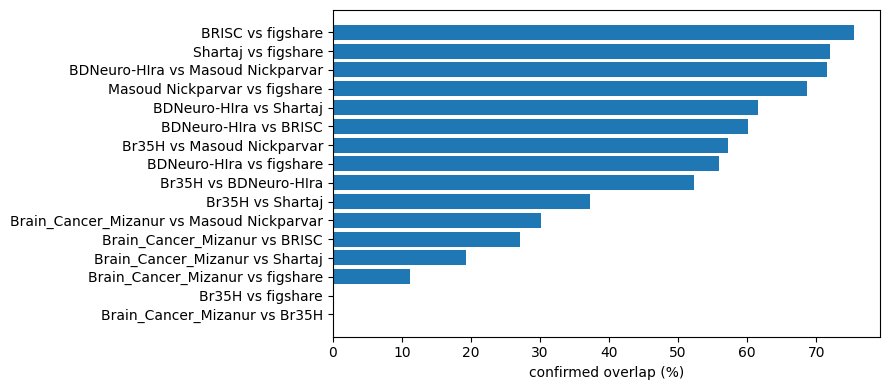

In [11]:
# Fig 2: cross-dataset overlap summary
plt.figure(figsize=(9,4))
ordered = cross_summary_df.sort_values('pct')
plt.barh(ordered['source']+' vs '+ordered['target'], ordered['pct'])
plt.xlabel('confirmed overlap (%)')
plt.tight_layout()
plt.savefig('/kaggle/working/fig2_cross_dataset_overlap.png', dpi=150, bbox_inches='tight')
plt.show()

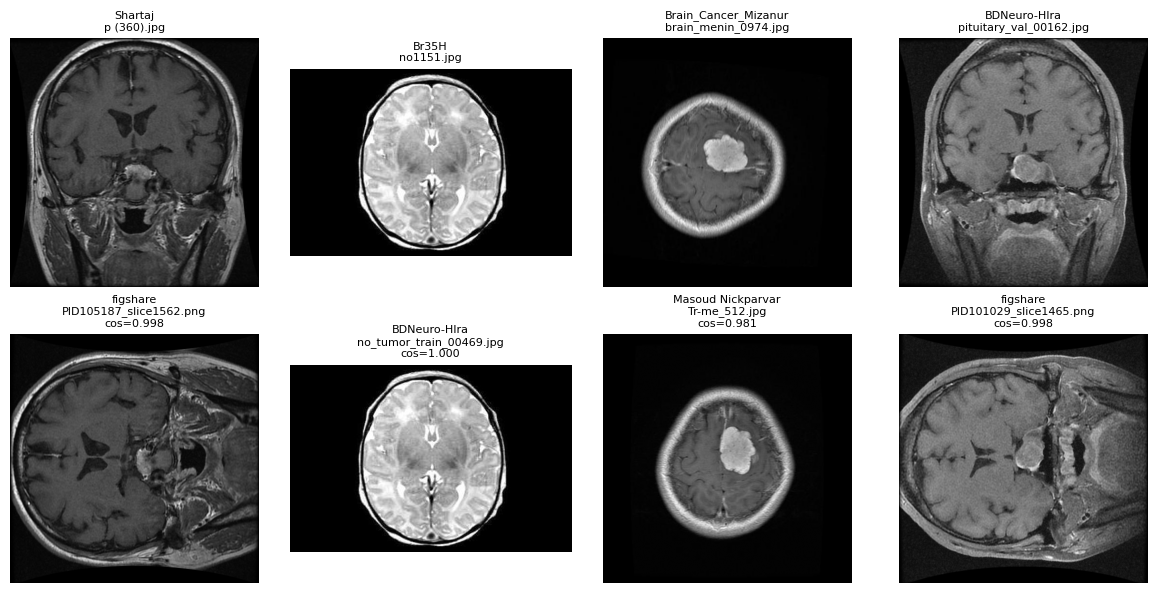

In [12]:
# Fig 2b: example CROSS-DATASET duplicate pairs (the undisclosed-overlap evidence)
# one example each from the pairs with no disclosed source: Sartaj, Br35H, BDNeuro-Hira, Mizanur

def show_cross_examples(examples, save_as=None):
    n = len(examples)
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6))
    if n == 1: axes = axes.reshape(2,1)
    for col, (label, row) in enumerate(examples):
        axes[0,col].imshow(Image.open(row['source_path']), cmap='gray'); axes[0,col].axis('off')
        axes[0,col].set_title(f"{row['source_dataset']}\n{row['source_file']}", fontsize=8)
        axes[1,col].imshow(Image.open(row['target_path']), cmap='gray'); axes[1,col].axis('off')
        axes[1,col].set_title(f"{row['target_dataset']}\n{row['target_file']}\ncos={row['cosine_sim']:.3f}", fontsize=8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()

examples = []
for src, tgt in [("Shartaj","figshare"), ("Br35H","BDNeuro-HIra"),
                  ("Brain_Cancer_Mizanur","Masoud Nickparvar"), ("BDNeuro-HIra","figshare")]:
    key = f"{src}__vs__{tgt}"
    if key in cross_results and len(cross_results[key]):
        row = cross_results[key].sort_values('cosine_sim', ascending=False).iloc[0]
        examples.append((key, row))

show_cross_examples(examples, save_as='/kaggle/working/fig2b_external_duplicates.png')

In [13]:
internal_summary = internal_df.groupby(['dataset','eval_split','category']).size().unstack(fill_value=0)
internal_summary['eval_size'] = [sizes.get((d,s),0) for d,s in internal_summary.index]
for cat in ['A_true_duplicate','B_adjacent_slice','C_false_alarm']:
    if cat not in internal_summary.columns:
        internal_summary[cat] = 0
    internal_summary[f'{cat}_pct'] = round(100*internal_summary[cat]/internal_summary['eval_size'],2)
internal_summary.to_csv("/kaggle/working/SUMMARY_internal_leakage.csv")
internal_summary

category                      A_true_duplicate  B_adjacent_slice  \
dataset           eval_split                                       
BDNeuro-HIra      test                       0                73   
                  val                        1                82   
BRISC             test                      94               154   
Masoud Nickparvar test                     210               326   
Shartaj           test                     222                22   

category                      C_false_alarm  eval_size  A_true_duplicate_pct  \
dataset           eval_split                                                   
BDNeuro-HIra      test                  245        889                  0.00   
                  val                   243        892                  0.11   
BRISC             test                  337       1000                  9.40   
Masoud Nickparvar test                  495       1600                 13.12   
Shartaj           test                   31        394                 56.35   

category                      B_adjacent_slice_pct  C_false_alarm_pct  
dataset           eval_split                                           
BDNeuro-HIra      test                        8.21              27.56  
                  val                         9.19              27.24  
BRISC             test                       15.40              33.70  
Masoud Nickparvar test                       20.38              30.94  
Shartaj           test                        5.58               7.87

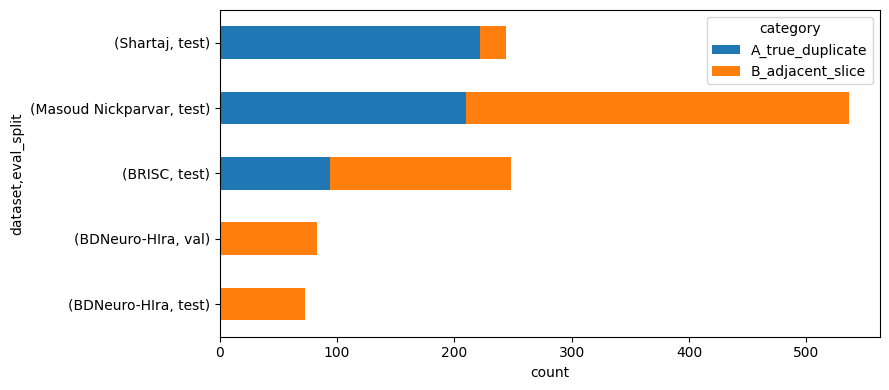

In [14]:
# Fig 3: internal leakage breakdown per dataset
plot_cols = [c for c in ['A_true_duplicate','B_adjacent_slice'] if c in internal_summary.columns]
internal_summary[plot_cols].plot(kind='barh', stacked=True, figsize=(9,4))
plt.xlabel('count')
plt.tight_layout()
plt.savefig('/kaggle/working/fig3_internal_leakage.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Manual validation sample

Stratified sample across cosine-similarity bins for 2-rater manual check. Label each pair independently: same image / same slice different look / different slice same scan / different scan. No scores shown while labeling.

In [15]:
all_cross = pd.concat(cross_results.values(), ignore_index=True)

def stratified_sample(df_in, col, bins, n_per_bin, seed=42):
    out = []
    for lo, hi in bins:
        chunk = df_in[(df_in[col]>=lo)&(df_in[col]<hi)]
        out.append(chunk.sample(n=min(n_per_bin,len(chunk)), random_state=seed))
    return pd.concat(out, ignore_index=True)

bins = [(0.95,0.97),(0.97,0.99),(0.99,1.001)]
manual_sample = stratified_sample(all_cross, 'cosine_sim', bins, n_per_bin=25)
manual_sample = manual_sample.sample(frac=1, random_state=1).reset_index(drop=True)  # shuffle
manual_sample['rater1_label'] = ''
manual_sample['rater2_label'] = ''
manual_sample[['source_dataset','target_dataset','source_file','target_file',
               'source_path','target_path','rater1_label','rater2_label']].to_csv(
    "/kaggle/working/MANUAL_VALIDATION_SHEET.csv", index=False)
print(f"{len(manual_sample)} pairs to label -> MANUAL_VALIDATION_SHEET.csv")
print("cosine_sim column intentionally left out of the export so raters aren't biased")

75 pairs to label -> MANUAL_VALIDATION_SHEET.csv
cosine_sim column intentionally left out of the export so raters aren't biased


In [16]:
# Contact sheet: all validation pairs, numbered, source|target side by side.
# Export as PNG pages so your rater can view/print without touching the notebook.

manual_sample = pd.read_csv("/kaggle/working/MANUAL_VALIDATION_SHEET.csv")

def make_contact_sheet(data, page, per_page=10):
    start = page * per_page
    chunk = data.iloc[start:start+per_page]
    if len(chunk) == 0:
        return
    fig, axes = plt.subplots(len(chunk), 2, figsize=(6, 2.2*len(chunk)))
    for row, (idx, r) in enumerate(chunk.iterrows()):
        axes[row,0].imshow(Image.open(r['source_path']), cmap='gray'); axes[row,0].axis('off')
        axes[row,1].imshow(Image.open(r['target_path']), cmap='gray'); axes[row,1].axis('off')
        axes[row,0].set_title(f"#{idx}  A", fontsize=9, loc='left')
        axes[row,1].set_title("B", fontsize=9, loc='left')
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/validation_sheet_page{page}.png", dpi=120, bbox_inches='tight')
    plt.close()
    print(f"saved page {page} ({len(chunk)} pairs, #{start}-#{start+len(chunk)-1})")

n_pages = (len(manual_sample) // 10) + 1
for p in range(n_pages):
    make_contact_sheet(manual_sample, p)

saved page 0 (10 pairs, #0-#9)
saved page 1 (10 pairs, #10-#19)
saved page 2 (10 pairs, #20-#29)
saved page 3 (10 pairs, #30-#39)
saved page 4 (10 pairs, #40-#49)
saved page 5 (10 pairs, #50-#59)
saved page 6 (10 pairs, #60-#69)
saved page 7 (5 pairs, #70-#74)


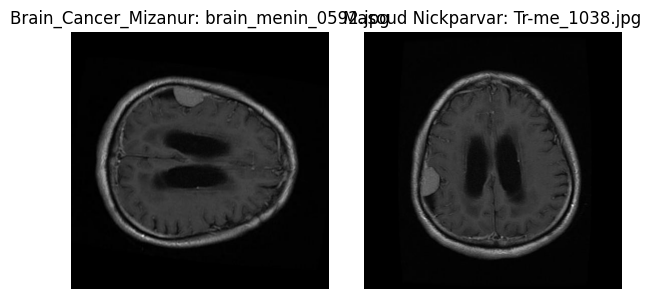

In [17]:
# viewer to go through the sample and fill labels in the sheet by hand afterward
def view_pair(idx):
    r = manual_sample.iloc[idx]
    fig, axes = plt.subplots(1,2,figsize=(6,3))
    axes[0].imshow(Image.open(r['source_path']), cmap='gray'); axes[0].axis('off')
    axes[0].set_title(f"{r['source_dataset']}: {r['source_file']}")
    axes[1].imshow(Image.open(r['target_path']), cmap='gray'); axes[1].axis('off')
    axes[1].set_title(f"{r['target_dataset']}: {r['target_file']}")
    plt.tight_layout(); plt.show()

view_pair(0)

## 6. Figshare patient-level split experiment

Same model, three ways: naive random split, patient-level split, cross-dataset test with duplicates removed. This needs a `PID` recoverable from each figshare filename - check the pattern below before running the rest.

In [18]:
fig_sample_names = df[df['dataset']=='figshare']['filename'].head(10).tolist()
print(fig_sample_names)
# confirm the PID pattern matches before running the next cell - adjust the regex if not

['PID110993_slice1107.png', 'PID112847_slice1008.png', 'PID105638_slice1764.png', 'PID99223_slice1634.png', 'PID98874_slice1432.png', 'PID97599_slice1595.png', 'PID99223_slice1450.png', 'PID103837_slice1530.png', 'PID112746_slice1258.png', 'PID106062_slice1035.png']


In [19]:
import re

def extract_pid(filename):
    m = re.match(r'^(PID[A-Za-z0-9]+)_slice', filename)
    return m.group(1) if m else None

fig_df = df[df['dataset']=='figshare'].copy()
fig_df['pid'] = fig_df['filename'].apply(extract_pid)

n_unmatched = fig_df['pid'].isna().sum()
n_patients = fig_df['pid'].nunique()
print(f"{n_unmatched} / {len(fig_df)} filenames did not match")
print(f"{n_patients} unique patients")
if n_unmatched > 0:
    print("unmatched examples:", fig_df[fig_df['pid'].isna()]['filename'].head(5).tolist())
assert n_unmatched == 0, "fix the regex before continuing - some filenames did not yield a PID"


0 / 3064 filenames did not match
233 unique patients


In [20]:
# verify: no patient ever appears in both train and test of the same fold
from sklearn.model_selection import GroupKFold

_gkf_check = GroupKFold(n_splits=5)
for fold, (tr_idx, te_idx) in enumerate(_gkf_check.split(fig_df, groups=fig_df['pid'])):
    train_pids = set(fig_df.iloc[tr_idx]['pid'])
    test_pids = set(fig_df.iloc[te_idx]['pid'])
    overlap = train_pids & test_pids
    print(f"fold {fold}: train patients={len(train_pids)}  test patients={len(test_pids)}  overlap={len(overlap)}")
    assert len(overlap) == 0, f"leak detected in fold {fold}"
print("confirmed: patient-level split is clean across all folds")

fold 0: train patients=187  test patients=46  overlap=0
fold 1: train patients=186  test patients=47  overlap=0
fold 2: train patients=186  test patients=47  overlap=0
fold 3: train patients=186  test patients=47  overlap=0
fold 4: train patients=187  test patients=46  overlap=0
confirmed: patient-level split is clean across all folds


In [21]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import time

label_map = {l:i for i,l in enumerate(sorted(fig_df['label'].unique()))}
fig_df['y'] = fig_df['label'].map(label_map)

def compute_mean_std(frame, sample_n=500):
    sample = frame.sample(n=min(sample_n,len(frame)), random_state=0)
    pixels = [np.array(Image.open(p).convert('L').resize((224,224)))/255.0 for p in sample['filepath']]
    arr = np.stack(pixels)
    return arr.mean(), arr.std()

fig_mean, fig_std = compute_mean_std(fig_df)
print(f"figshare mean={fig_mean:.4f} std={fig_std:.4f}")

class MRIDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        base = [T.Resize((224,224))]
        if augment:
            base += [T.RandomHorizontalFlip(0.5), T.RandomRotation(10), T.ColorJitter(0.1,0.1)]
        base += [T.Grayscale(3), T.ToTensor(), T.Normalize(mean=[fig_mean]*3, std=[fig_std]*3)]
        self.tf = T.Compose(base)
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row['filepath']).convert('L')
        return self.tf(img), row['y']

def build_model(n_classes):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m.to(device)

def train_and_eval(train_df, test_df, epochs=15, lr=1e-4):
    n_classes = fig_df['y'].nunique()
    model = build_model(n_classes)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    lossf = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler()

    train_loader = DataLoader(MRIDataset(train_df, augment=True), batch_size=64, shuffle=True,
                               num_workers=2, pin_memory=True)
    test_loader = DataLoader(MRIDataset(test_df, augment=False), batch_size=64,
                              num_workers=2, pin_memory=True)

    for ep in range(epochs):
        t0 = time.time()
        model.train()
        total_loss = 0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = lossf(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            total_loss += loss.item()
        print(f"  epoch {ep+1}/{epochs}  loss={total_loss/len(train_loader):.4f}  ({time.time()-t0:.0f}s)")

    model.eval()
    preds, actual = [], []
    with torch.no_grad():
        for x,y in test_loader:
            x = x.to(device)
            p = model(x).argmax(1).cpu().numpy()
            preds.extend(p); actual.extend(y.numpy())

    return {
        'acc': accuracy_score(actual, preds),
        'f1_macro': f1_score(actual, preds, average='macro'),
        'cm': confusion_matrix(actual, preds),
        'report': classification_report(actual, preds, target_names=list(label_map.keys()), output_dict=True),
    }

figshare mean=0.1572 std=0.1660


In [22]:
def run_kfold(strategy, n_splits=5, epochs=15):
    results = []
    if strategy == 'patient':
        splitter = GroupKFold(n_splits=n_splits).split(fig_df, groups=fig_df['pid'])
    else:
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42).split(fig_df, fig_df['y'])

    for fold, (tr_idx, te_idx) in enumerate(splitter):
        print(f"fold {fold}:")
        r = train_and_eval(fig_df.iloc[tr_idx], fig_df.iloc[te_idx], epochs=epochs)
        r['fold'] = fold
        results.append(r)
        print(f"  -> acc={r['acc']:.4f} f1={r['f1_macro']:.4f}")
    return results

print("=== naive split (Stratified K-Fold, patient identity ignored) ===")
naive_results = run_kfold('naive')

print("\n=== patient split (Group K-Fold) ===")
patient_results = run_kfold('patient')

naive_accs = [r['acc'] for r in naive_results]
patient_accs = [r['acc'] for r in patient_results]
print(f"\nnaive:   {np.mean(naive_accs):.4f} +/- {np.std(naive_accs):.4f}")
print(f"patient: {np.mean(patient_accs):.4f} +/- {np.std(patient_accs):.4f}")
print(f"gap: {100*(np.mean(naive_accs)-np.mean(patient_accs)):.2f} points")

=== naive split (Stratified K-Fold, patient identity ignored) ===
fold 0:


/tmp/ipykernel_58/2762410406.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_58/2762410406.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6393  (13s)
  epoch 2/15  loss=0.2612  (11s)
  epoch 3/15  loss=0.1855  (11s)
  epoch 4/15  loss=0.1301  (11s)
  epoch 5/15  loss=0.1108  (11s)
  epoch 6/15  loss=0.0946  (11s)
  epoch 7/15  loss=0.0745  (11s)
  epoch 8/15  loss=0.0581  (11s)
  epoch 9/15  loss=0.0532  (11s)
  epoch 10/15  loss=0.0644  (11s)
  epoch 11/15  loss=0.0447  (11s)
  epoch 12/15  loss=0.0320  (11s)
  epoch 13/15  loss=0.0372  (11s)
  epoch 14/15  loss=0.0213  (11s)
  epoch 15/15  loss=0.0258  (11s)
  -> acc=0.9657 f1=0.9622
fold 1:


/tmp/ipykernel_58/2762410406.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_58/2762410406.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6422  (11s)
  epoch 2/15  loss=0.2690  (11s)
  epoch 3/15  loss=0.1840  (11s)
  epoch 4/15  loss=0.1353  (11s)
  epoch 5/15  loss=0.0936  (11s)
  epoch 6/15  loss=0.0891  (11s)
  epoch 7/15  loss=0.0708  (11s)
  epoch 8/15  loss=0.0620  (11s)
  epoch 9/15  loss=0.0659  (11s)
  epoch 10/15  loss=0.0566  (11s)
  epoch 11/15  loss=0.0346  (11s)
  epoch 12/15  loss=0.0385  (11s)
  epoch 13/15  loss=0.0316  (11s)
  epoch 14/15  loss=0.0255  (11s)
  epoch 15/15  loss=0.0263  (11s)
  -> acc=0.9445 f1=0.9385
fold 2:


...

  epoch 1/15  loss=0.6066  (11s)
  epoch 2/15  loss=0.2297  (11s)
  epoch 3/15  loss=0.1574  (11s)
  epoch 4/15  loss=0.1137  (11s)
  epoch 5/15  loss=0.0988  (11s)
  epoch 6/15  loss=0.0885  (11s)
  epoch 7/15  loss=0.0640  (11s)
  epoch 8/15  loss=0.0549  (11s)
  epoch 9/15  loss=0.0446  (14s)
  epoch 10/15  loss=0.0379  (12s)
  epoch 11/15  loss=0.0478  (11s)
  epoch 12/15  loss=0.0410  (11s)
  epoch 13/15  loss=0.0407  (11s)
  epoch 14/15  loss=0.0374  (11s)
  epoch 15/15  loss=0.0236  (11s)
  -> acc=0.9396 f1=0.9310
fold 3:


/tmp/ipykernel_58/2762410406.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_58/2762410406.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6240  (11s)
  epoch 2/15  loss=0.2428  (11s)
  epoch 3/15  loss=0.1559  (11s)
  epoch 4/15  loss=0.1083  (11s)
  epoch 5/15  loss=0.1054  (11s)
  epoch 6/15  loss=0.0779  (11s)
  epoch 7/15  loss=0.0424  (11s)
  epoch 8/15  loss=0.0596  (11s)
  epoch 9/15  loss=0.0409  (11s)
  epoch 10/15  loss=0.0371  (11s)
  epoch 11/15  loss=0.0344  (11s)
  epoch 12/15  loss=0.0315  (11s)
  epoch 13/15  loss=0.0333  (11s)
  epoch 14/15  loss=0.0301  (11s)
  epoch 15/15  loss=0.0234  (11s)
  -> acc=0.9086 f1=0.9107
fold 4:


/tmp/ipykernel_58/2762410406.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_58/2762410406.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6305  (11s)
  epoch 2/15  loss=0.2503  (11s)
  epoch 3/15  loss=0.1787  (11s)
  epoch 4/15  loss=0.1329  (11s)
  epoch 5/15  loss=0.0829  (11s)
  epoch 6/15  loss=0.0791  (11s)
  epoch 7/15  loss=0.0753  (11s)
  epoch 8/15  loss=0.0574  (11s)
  epoch 9/15  loss=0.0407  (11s)
  epoch 10/15  loss=0.0375  (11s)
  epoch 11/15  loss=0.0429  (11s)
  epoch 12/15  loss=0.0401  (11s)
  epoch 13/15  loss=0.0394  (11s)
  epoch 14/15  loss=0.0243  (11s)
  epoch 15/15  loss=0.0175  (11s)
  -> acc=0.9183 f1=0.9032

naive:   0.9657 +/- 0.0117
patient: 0.9230 +/- 0.0141
gap: 4.28 points


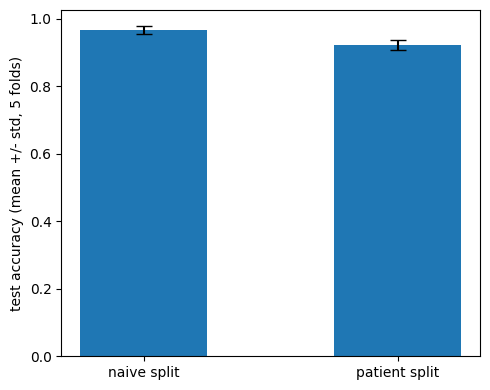

In [23]:
# Fig 4: naive vs patient split accuracy
plt.figure(figsize=(5,4))
plt.bar(['naive split','patient split'],
        [np.mean(naive_accs), np.mean(patient_accs)],
        yerr=[np.std(naive_accs), np.std(patient_accs)], capsize=6, width=0.5)
plt.ylabel('test accuracy (mean +/- std, 5 folds)')
plt.tight_layout()
plt.savefig('/kaggle/working/fig4_split_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

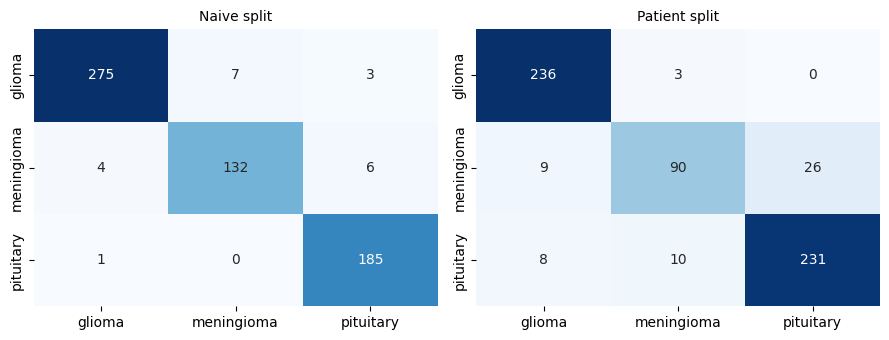

In [24]:
# Fig 5: confusion matrices, fold 0 of each strategy
import seaborn as sns

labels = list(label_map.keys())
fig, axes = plt.subplots(1,2, figsize=(9,3.5))
sns.heatmap(naive_results[0]['cm'], annot=True, fmt='d', xticklabels=labels, yticklabels=labels, ax=axes[0], cmap='Blues', cbar=False)
axes[0].set_title('Naive split', fontsize=10)
sns.heatmap(patient_results[0]['cm'], annot=True, fmt='d', xticklabels=labels, yticklabels=labels, ax=axes[1], cmap='Blues', cbar=False)
axes[1].set_title('Patient split', fontsize=10)
plt.tight_layout()
plt.savefig('/kaggle/working/fig5_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
import json as _json

def avg_report_across_folds(results):
    reports = [r['report'] for r in results]
    classes = list(label_map.keys())
    rows = []
    for cls in classes:
        rows.append({
            'class': cls,
            'precision': np.mean([r[cls]['precision'] for r in reports]),
            'recall': np.mean([r[cls]['recall'] for r in reports]),
            'f1': np.mean([r[cls]['f1-score'] for r in reports]),
        })
    return pd.DataFrame(rows)

naive_class_metrics = avg_report_across_folds(naive_results)
patient_class_metrics = avg_report_across_folds(patient_results)

naive_class_metrics.to_csv("/kaggle/working/naive_per_class_metrics.csv", index=False)
patient_class_metrics.to_csv("/kaggle/working/patient_per_class_metrics.csv", index=False)

with open('/kaggle/working/naive_report_fold0.json','w') as f:
    _json.dump(naive_results[0]['report'], f, indent=2)
with open('/kaggle/working/patient_report_fold0.json','w') as f:
    _json.dump(patient_results[0]['report'], f, indent=2)

print("naive split - per class (avg over 5 folds)")
print(naive_class_metrics)
print("\npatient split - per class (avg over 5 folds)")
print(patient_class_metrics)

naive split - per class (avg over 5 folds)
        class  precision    recall        f1
0      glioma   0.975365  0.967736  0.971452
1  meningioma   0.927301  0.936430  0.931386
2   pituitary   0.982108  0.984946  0.983413

patient split - per class (avg over 5 folds)
        class  precision    recall        f1
0      glioma   0.960227  0.930865  0.944279
1  meningioma   0.824641  0.880762  0.846811
2   pituitary   0.950318  0.953711  0.951298


## 7. Zip everything for download

In [26]:
import shutil, os

FILES_TO_ZIP = [
    "manifest.csv",
    "internal_leakage_final.csv",
    "SUMMARY_internal_leakage.csv",
    "SUMMARY_cross_dataset.csv",
    "MANUAL_VALIDATION_SHEET.csv",
    "naive_report_fold0.json",
    "patient_report_fold0.json",
    "naive_per_class_metrics.csv",
    "patient_per_class_metrics.csv",
    "fig1_example_duplicates.png",
    "fig2b_external_duplicates.png",
    "fig2_cross_dataset_overlap.png",
    "fig3_internal_leakage.png",
    "fig4_split_comparison.png",
    "fig5_confusion_matrices.png",
]

# all the individual cross-dataset comparison CSVs too (cross_*.csv)
cross_csvs = [f for f in os.listdir("/kaggle/working") if f.startswith("cross_") and f.endswith(".csv")]
contact_sheets = [f for f in os.listdir("/kaggle/working") if f.startswith("validation_sheet_page")]

ZIP_DIR = "/kaggle/working/paper_outputs"
os.makedirs(ZIP_DIR, exist_ok=True)

all_files = FILES_TO_ZIP + cross_csvs + contact_sheets
copied, missing = [], []
for fname in all_files:
    src = os.path.join("/kaggle/working", fname)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(ZIP_DIR, fname))
        copied.append(fname)
    else:
        missing.append(fname)

shutil.make_archive("/kaggle/working/brain_tumor_leakage_audit_outputs", 'zip', ZIP_DIR)

print(f"zipped {len(copied)} files -> brain_tumor_leakage_audit_outputs.zip")
if missing:
    print(f"not found (run the earlier cells first if these are missing): {missing}")

zipped 39 files -> brain_tumor_leakage_audit_outputs.zip
